In [1]:
import os
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.init as init
from torch.autograd import grad

def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.enabled = True
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"随机种子设置为: {seed}")

set_random_seed(42)
torch.set_default_dtype(torch.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

随机种子设置为: 42
Using device: cuda


In [2]:
def get_physical_parameters():
    params = {
        "rho": 960.0,
        "mu": 8.526e-4,
        "dp": 1e-4,
        "L": 0.02,
        "p_outlet": 1e5,
        "v_inlet": 1.0 / 960.0,
        # 双区域孔隙率
        'eps1': 0.2,         # 区域 1 （方形板背景）
        'eps2': 0.5,         # 区域 2 （圆形区域）
        # 圆形界面几何
        "xc": 0.01,
        "yc": 0.01,
        "R": 0.003,
        # 特征尺度
        "mu_0": 8.526e-4,
        "k_0": 1e-12,
        "V_0": 1e-3,
        "L_0": 0.02,
    }
    params["P_0"] = (params["L_0"] * params["mu_0"] * params["V_0"]) / params["k_0"]
    return params

def permeability(eps, dp):
    """Ergun 关系：K = dp^2 * eps^3 / [150 (1-eps)^2]"""
    return (dp ** 2) * (eps ** 3) / (150.0 * (1.0 - eps) ** 2)
params = get_physical_parameters()
eps1 = params["eps1"]
eps2 = params["eps2"]

LAMBDA_GAMMA = 1.0

# ============================================================
# 反问题：孔隙率固定，只反演圆心 (xc, yc) 和半径 R
# 训练变量采用无量纲原始参数，并用 Sigmoid/Tanh 保证圆始终位于计算域内。
# ============================================================
params["xc_true"] = params["xc"]
params["yc_true"] = params["yc"]
params["R_true"] = params["R"]

GEOM_INIT = {"xc": 0.009, "yc": 0.011, "R": 0.004}
R_STAR_MIN, R_STAR_MAX = 0.10, 0.50
GEOM_MARGIN_STAR = 0.02

def _logit(x):
    x = float(np.clip(x, 1e-6, 1.0 - 1e-6))
    return math.log(x / (1.0 - x))

def _atanh_safe(x):
    x = float(np.clip(x, -0.999999, 0.999999))
    return np.arctanh(x)

R0_star = 2.0 * GEOM_INIT["R"] / params["L"]           #star都是无量纲的物理量
xc0_star = 2.0 * GEOM_INIT["xc"] / params["L"] - 1.0
yc0_star = 2.0 * GEOM_INIT["yc"] / params["L"] - 1.0
R0_ratio = (R0_star - R_STAR_MIN) / (R_STAR_MAX - R_STAR_MIN)
center_limit0 = 1.0 - R0_star - GEOM_MARGIN_STAR      #圆心容许移动的距离

geom_raw_xc = nn.Parameter(torch.tensor(_atanh_safe(xc0_star / center_limit0), device=device))
geom_raw_yc = nn.Parameter(torch.tensor(_atanh_safe(yc0_star / center_limit0), device=device))
geom_raw_R = nn.Parameter(torch.tensor(_logit(R0_ratio), device=device))

def current_geometry_star():
    R_star = R_STAR_MIN + (R_STAR_MAX - R_STAR_MIN) * torch.sigmoid(geom_raw_R)
    center_limit = 1.0 - R_star - GEOM_MARGIN_STAR
    xc_star = center_limit * torch.tanh(geom_raw_xc)
    yc_star = center_limit * torch.tanh(geom_raw_yc)
    return xc_star, yc_star, R_star

def current_geometry_phys():
    xc_star, yc_star, R_star = current_geometry_star()
    xc = 0.5 * (xc_star + 1.0) * params["L"]
    yc = 0.5 * (yc_star + 1.0) * params["L"]
    R = 0.5 * R_star * params["L"]
    return xc, yc, R

@torch.no_grad()
def sync_geometry_to_params():
    xc, yc, R = current_geometry_phys()
    params["xc"] = float(xc.cpu())
    params["yc"] = float(yc.cpu())
    params["R"] = float(R.cpu())

sync_geometry_to_params()
print(f"几何初值: xc={params['xc']:.6f}, yc={params['yc']:.6f}, R={params['R']:.6f}")

几何初值: xc=0.009000, yc=0.011000, R=0.004000


In [3]:
class SimplePINN(nn.Module):
    def __init__(self, in_dim=2, out_dim=3, hidden_dim=20, num_hidden_layers=6):
        super().__init__()
        layers = [nn.Linear(in_dim, hidden_dim), nn.Tanh()]
        for _ in range(num_hidden_layers - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.Tanh()]
        layers.append(nn.Linear(hidden_dim, out_dim))
        self.net = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        for i, m in enumerate(self.net):
            if isinstance(m, nn.Linear):
                gain = init.calculate_gain("tanh") if i + 1 < len(self.net) and isinstance(self.net[i + 1], nn.Tanh) else 1.0
                init.xavier_uniform_(m.weight, gain=gain)
                init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


net_out = SimplePINN().to(device)   # 圆外区域网络
net_in = SimplePINN().to(device)    # 圆内区域网络

In [4]:
def phys_to_star(x_phys, y_phys, params, device):
    """物理坐标 [0,L] 转无量纲坐标 [-1,1]。"""
    L = params["L"]
    x_star = np.asarray(x_phys, dtype=np.float64) / L * 2.0 - 1.0
    y_star = np.asarray(y_phys, dtype=np.float64) / L * 2.0 - 1.0
    x_star = torch.tensor(x_star, dtype=torch.get_default_dtype(), device=device).view(-1, 1)
    y_star = torch.tensor(y_star, dtype=torch.get_default_dtype(), device=device).view(-1, 1)
    return x_star, y_star

def star_to_phys(coords_star, params):
    L = params["L"]
    x_phys = (coords_star[:, 0] + 1.0) * 0.5 * L
    y_phys = (coords_star[:, 1] + 1.0) * 0.5 * L
    return x_phys, y_phys

In [5]:
def make_cell(x_min, x_max, y_min, y_max, level=0, region=""):
    return {
        "x_min": float(x_min), "x_max": float(x_max),
        "y_min": float(y_min), "y_max": float(y_max),
        "level": int(level), "region": region,
        "eta": 0.0, "eta2": 0.0,
        "is_interface": False, #默认是false
    }

def point_region_by_circle(x, y, params):
    "判断点在圆内还是圆外"
    r2 = (x - params["xc"]) ** 2 + (y - params["yc"]) ** 2
    return "in" if r2 < params["R"] ** 2 else "out"

def classify_cell_by_center(cell, params):
    "取中心点"
    cx = 0.5 * (cell["x_min"] + cell["x_max"])
    cy = 0.5 * (cell["y_min"] + cell["y_max"])
    return point_region_by_circle(cx, cy, params)

def cell_size(cell):
    "找网格的长度"
    return max(cell["x_max"] - cell["x_min"], cell["y_max"] - cell["y_min"])


def cell_area(cell):
    "面积"
    return (cell["x_max"] - cell["x_min"]) * (cell["y_max"] - cell["y_min"])


def build_initial_cells(params, nx0=10, ny0=10):
    "建立初始网格"
    L = params["L"]
    dx = L / nx0
    dy = L / ny0
    cells = []
    for i in range(nx0):
        for j in range(ny0):
            x0, x1 = i * dx, (i + 1) * dx
            y0, y1 = j * dy, (j + 1) * dy
            c = make_cell(x0, x1, y0, y1, level=0)
            c["region"] = classify_cell_by_center(c, params)
            cells.append(c)
    return cells


def split_cell(cell, params=None):
    "分裂单元，并且归属到内还是外"
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xm, ym = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
    boxes = [
        (x0, xm, y0, ym), (xm, x1, y0, ym),
        (x0, xm, ym, y1), (xm, x1, ym, y1),
    ]
    children = []
    for xa, xb, ya, yb in boxes:
        cc = make_cell(xa, xb, ya, yb, level=cell["level"] + 1)
        if params is not None:
            cc["region"] = classify_cell_by_center(cc, params)
        children.append(cc)
    return children

In [6]:
def cell_intersects_circle(cell, params, tol=1e-14):
    """判断 cell 是否被圆形界面穿过。是否是界面网格"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xc, yc, R = params["xc"], params["yc"], params["R"]

    x_closest = min(max(xc, x0), x1)
    y_closest = min(max(yc, y0), y1)
    dmin = math.hypot(x_closest - xc, y_closest - yc)

    corners = [(x0, y0), (x1, y0), (x0, y1), (x1, y1)]
    dmax = max(math.hypot(x - xc, y - yc) for x, y in corners)
    return (dmin <= R + tol) and (dmax >= R - tol)


def circle_cell_intersections(cell, params, tol=1e-12):
    """求圆形界面和矩形 cell 边界的交点。"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xc, yc, R = params["xc"], params["yc"], params["R"]
    pts = []

    for x in (x0, x1):
        val = R ** 2 - (x - xc) ** 2
        if val >= -tol:
            dy = math.sqrt(max(val, 0.0))
            for y in (yc - dy, yc + dy):
                if y0 - tol <= y <= y1 + tol:
                    pts.append((x, min(max(y, y0), y1)))

    for y in (y0, y1):
        val = R ** 2 - (y - yc) ** 2
        if val >= -tol:
            dx = math.sqrt(max(val, 0.0))
            for x in (xc - dx, xc + dx):
                if x0 - tol <= x <= x1 + tol:
                    pts.append((min(max(x, x0), x1), y))

    unique = []  #去重 
    for p in pts:
        if not any((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2 < tol ** 2 for q in unique):
            unique.append(p)
    return unique

In [7]:
def local_interface_geometry(cell, params):
    """
    返回界面 cell 内局部界面信息：
    - 是否界面 cell
    - p_if：圆弧中点，作为界面训练点
    - length_if：两个交点连线长度，近似 |Gamma cap K|
    - normal：圆内指向圆外的单位法向
    """
    if not cell_intersects_circle(cell, params): 
        return False, None, 0.0, None  #不是界面单元；无界面中点；界面长度为 0；无界面法向量

    pts = circle_cell_intersections(cell, params)
    if len(pts) < 2:  #因为算圆弧的话，就是需要2个点啊
        return False, None, 0.0, None   #该单元格不是有效界面单元，不存在圆弧中点 p_if，界面长度为 0，没有界面单位法向量 normal

    max_d2 = -1.0
    A, B = pts[0], pts[1]
    for i in range(len(pts)):
        for j in range(i + 1, len(pts)):
            d2 = (pts[i][0] - pts[j][0]) ** 2 + (pts[i][1] - pts[j][1]) ** 2
            if d2 > max_d2:
                max_d2 = d2
                A, B = pts[i], pts[j]  ##返回的是合格的交点

    length_if = math.sqrt(max_d2)
    if length_if < 1e-14:
        return False, None, 0.0, None

    xc, yc, R = params["xc"], params["yc"], params["R"]
    ta = math.atan2(A[1] - yc, A[0] - xc)  #极角
    tb = math.atan2(B[1] - yc, B[0] - xc)
    diff = (tb - ta + math.pi) % (2.0 * math.pi) - math.pi
    tm = ta + 0.5 * diff

    p_if = (xc + R * math.cos(tm), yc + R * math.sin(tm))  #中点坐标
    normal = (math.cos(tm), math.sin(tm))  #外法线
    return True, p_if, length_if, normal

In [8]:
def estimate_area_fractions_by_sampling(cell, params, n_side=7, min_frac=1e-6):
    """
    用辅助撒点估计界面 cell 内两侧面积比例。
    """
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xs = np.linspace(x0 + 0.5 * (x1 - x0) / n_side, x1 - 0.5 * (x1 - x0) / n_side, n_side)
    ys = np.linspace(y0 + 0.5 * (y1 - y0) / n_side, y1 - 0.5 * (y1 - y0) / n_side, n_side)

    n_in = 0
    n_total = n_side * n_side
    for x in xs:
        for y in ys:
            if point_region_by_circle(x, y, params) == "in":
                n_in += 1

    frac_in = n_in / n_total
    frac_out = 1.0 - frac_in

    # 防止极小切割区域被采样漏掉，给一个极小正权重
    frac_in = max(frac_in, min_frac)
    frac_out = max(frac_out, min_frac)
    s = frac_in + frac_out
    return frac_out / s, frac_in / s


def find_point_in_cell_region(cell, params, desired_region, p_if=None, normal=None):
    """在界面 cell 内找一个属于 desired_region 的 PDE 点。"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    h = cell_size(cell)
    eps = 1e-12 * params["L"]

    # 优先从界面点沿法向两侧取点
    if p_if is not None and normal is not None:
        sign = 1.0 if desired_region == "out" else -1.0
        for fac in (0.25, 0.18, 0.12, 0.08, 0.04, 0.02, 0.01, 0.005, 0.001, 1e-4, 1e-5, 1e-6):
            x = p_if[0] + sign * fac * h * normal[0]
            y = p_if[1] + sign * fac * h * normal[1]
            if x0 + eps <= x <= x1 - eps and y0 + eps <= y <= y1 - eps:
                if point_region_by_circle(x, y, params) == desired_region:
                    return x, y

    # 兜底：在 cell 内找一个对应区域点
    xs = np.linspace(x0 + 0.15 * (x1 - x0), x1 - 0.15 * (x1 - x0), 5)
    ys = np.linspace(y0 + 0.15 * (y1 - y0), y1 - 0.15 * (y1 - y0), 5)
    best = None
    best_dist = -1.0
    for x in xs:
        for y in ys:
            if point_region_by_circle(x, y, params) == desired_region:
                dist = abs(math.hypot(x - params["xc"], y - params["yc"]) - params["R"])
                if dist > best_dist:
                    best = (x, y)
                    best_dist = dist
    if best is not None:
        return best

    # 几何保证型兜底：不再错误地返回单元中心。
    # q_in 是矩形内距圆心最近的点；q_out 是距圆心最远的角点。
    # 对真正的切割单元，二者严格位于圆的两侧。在线段 q_in--q_out 上二分圆界面，
    # 再取相应半段的中点，可保证返回点仍在矩形内且属于指定子域。
    q_in = np.array([
        min(max(params["xc"], x0), x1),
        min(max(params["yc"], y0), y1),
    ], dtype=np.float64)
    corners = np.array([
        [x0, y0], [x1, y0], [x0, y1], [x1, y1]
    ], dtype=np.float64)
    center = np.array([params["xc"], params["yc"]], dtype=np.float64)
    q_out = corners[np.argmax(np.sum((corners - center) ** 2, axis=1))]

    def signed_circle_value(point):
        return ((point[0] - params["xc"]) ** 2
                + (point[1] - params["yc"]) ** 2
                - params["R"] ** 2)

    s_in = signed_circle_value(q_in)
    s_out = signed_circle_value(q_out)
    if not (s_in < 0.0 and s_out > 0.0):
        raise RuntimeError(
            f"无法在切割单元中构造两侧见证点: desired={desired_region}, "
            f"s_in={s_in:.3e}, s_out={s_out:.3e}, cell={cell}")

    left = q_in.copy()    # 始终在圆内
    right = q_out.copy()  # 始终在圆外
    for _ in range(80):
        middle = 0.5 * (left + right)
        if signed_circle_value(middle) < 0.0:
            left = middle
        else:
            right = middle

    if desired_region == "in":
        point = 0.5 * (q_in + left)
    else:
        point = 0.5 * (q_out + right)
    return float(point[0]), float(point[1])

In [9]:
def sample_points_from_matched_cells(cells, params, device, verbose=True):
    out_x, out_y = [], []
    in_x, in_y = [], []
    if_x, if_y, if_theta = [], [], []

    out_cells_plot, in_cells_plot = [], []
    n_interface = 0

    for c in cells:
        c["region"] = classify_cell_by_center(c, params)
        if c["region"] == "in":
            in_cells_plot.append(c)
        else:
            out_cells_plot.append(c)

        is_if, p_if, length_if, normal = local_interface_geometry(c, params)
        c["is_interface"] = bool(is_if)
        c["interface_length"] = float(length_if)

        if is_if:
            n_interface += 1
            if_x.append(p_if[0])
            if_y.append(p_if[1])
            if_theta.append(math.atan2(p_if[1] - params["yc"], p_if[0] - params["xc"]))

            p_out = find_point_in_cell_region(c, params, "out", p_if=p_if, normal=normal)
            p_in = find_point_in_cell_region(c, params, "in", p_if=p_if, normal=normal)
            out_x.append(p_out[0]); out_y.append(p_out[1])
            in_x.append(p_in[0]); in_y.append(p_in[1])
        else:
            cx = 0.5 * (c["x_min"] + c["x_max"])
            cy = 0.5 * (c["y_min"] + c["y_max"])
            if c["region"] == "in":
                in_x.append(cx); in_y.append(cy)
            else:
                out_x.append(cx); out_y.append(cy)

    out_x = np.asarray(out_x, dtype=np.float64); out_y = np.asarray(out_y, dtype=np.float64)
    in_x = np.asarray(in_x, dtype=np.float64); in_y = np.asarray(in_y, dtype=np.float64)
    if_x = np.asarray(if_x, dtype=np.float64); if_y = np.asarray(if_y, dtype=np.float64)
    if_theta = np.asarray(if_theta, dtype=np.float64)

    x_out, y_out = phys_to_star(out_x, out_y, params, device)
    x_in, y_in = phys_to_star(in_x, in_y, params, device)
    x_if, y_if = phys_to_star(if_x, if_y, params, device)

    out_sample = {"x": x_out, "y": y_out, "x_phys": out_x, "y_phys": out_y}
    in_sample = {"x": x_in, "y": y_in, "x_phys": in_x, "y_phys": in_y}
    interface_sample = {"theta": if_theta, "x": x_if, "y": y_if, "x_phys": if_x, "y_phys": if_y}

    if verbose:
        print("========== 基于界面 cell 的匹配采样完成 ==========")
        print(f"leaf cell 数量: {len(cells)}")
        print(f"界面 cell 数量: {n_interface}")
        print(f"孔外 PDE 点数量: {len(out_x)}")
        print(f"孔内 PDE 点数量: {len(in_x)}")
        print(f"界面点数量: {len(if_x)}")
        print("==============================================")
    return out_sample, in_sample, interface_sample, out_cells_plot, in_cells_plot

In [10]:
def plot_cells(ax, cells, edgecolor="0.35", linewidth=0.4, alpha=0.8):
    for c in cells:
        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=edgecolor, linewidth=linewidth, alpha=alpha)


def plot_adaptive_sampling_circle(out_cells, in_cells, out_sample, in_sample, interface_sample, params,
                                  title="Adaptive sampling mesh", save_path=None):
    L = params["L"]
    fig, ax = plt.subplots(figsize=(7, 7))
    plot_cells(ax, out_cells, edgecolor="0.25", linewidth=0.35, alpha=0.65)
    plot_cells(ax, in_cells, edgecolor="0.25", linewidth=0.35, alpha=0.85)

    ax.scatter(out_sample["x_phys"], out_sample["y_phys"], s=4, alpha=0.45, label="PDE points outside")
    ax.scatter(in_sample["x_phys"], in_sample["y_phys"], s=4, alpha=0.55, label="PDE points inside")
    ax.scatter(interface_sample["x_phys"], interface_sample["y_phys"], s=9, alpha=0.85, marker="x", label="Interface points")
    ax.plot([0, L, L, 0, 0], [0, 0, L, L, 0], "k-", linewidth=1.2)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"采样网格图已保存: {save_path}")
    plt.show()


def export_mesh_data_to_folder(save_root, round_label, out_cells, in_cells, out_sample, in_sample, interface_sample):
    sub_dir = os.path.join(save_root, round_label)
    os.makedirs(sub_dir, exist_ok=True)

    pd.DataFrame({"x(m)": out_sample["x_phys"], "y(m)": out_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "01_PDE_outside.csv"), index=False)
    pd.DataFrame({"x(m)": in_sample["x_phys"], "y(m)": in_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "02_PDE_inside.csv"), index=False)
    pd.DataFrame({"x(m)": interface_sample["x_phys"], "y(m)": interface_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "03_interface_points.csv"), index=False)

    grid_lines = []
    for c in out_cells + in_cells:
        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        grid_lines += [[x0, y0], [x1, y0], [x1, y1], [x0, y1], [x0, y0], [np.nan, np.nan]]
    arr = np.array(grid_lines)
    pd.DataFrame({"x_grid(m)": arr[:, 0], "y_grid(m)": arr[:, 1]}).to_csv(os.path.join(sub_dir, "04_mesh_grid_lines.csv"), index=False)
    print(f"✅ 网格数据导出完成 | 文件夹：{sub_dir}")
    return sub_dir

In [11]:
def gradients(y, x):
    return grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True)[0]

def forward_with_hard_bc(net, coords, params):
    raw = net(coords)
    u_tilde, v_tilde, p_tilde = raw[:, 0:1], raw[:, 1:2], raw[:, 2:3]
    x, y = coords[:, 0:1], coords[:, 1:2]
    v_in_star = params["v_inlet"] / params["V_0"]
    p_out_star = params["p_outlet"] / params["P_0"]

    wall_mask = (1.0 - x ** 2) #*(1.0 + y)
    u_star = wall_mask * u_tilde
    v_star = v_in_star + (1.0 + y) * v_tilde
    p_star = p_out_star + (1.0 - y) * p_tilde
    return u_star, v_star, p_star


def forward_inside_free(net, coords):
    raw = net(coords)
    return raw[:, 0:1], raw[:, 1:2], raw[:, 2:3]

In [12]:
def governing_equations_region(net, x_star, y_star, params, region):
    x_star = x_star.view(-1, 1).to(device)
    y_star = y_star.view(-1, 1).to(device)
    coords = torch.cat([x_star, y_star], dim=1)
    coords.requires_grad_(True)

    if region == "out":
        u, v, p = forward_with_hard_bc(net, coords, params)
        eps = eps1
    elif region == "in":
        u, v, p = forward_inside_free(net, coords)
        eps = eps2
    else:
        raise ValueError("region 必须是 'out' 或 'in'")

    gu = gradients(u, coords)
    gv = gradients(v, coords)
    gp = gradients(p, coords)
    u_x, u_y = gu[:, 0:1], gu[:, 1:2]
    v_x, v_y = gv[:, 0:1], gv[:, 1:2]
    p_x, p_y = gp[:, 0:1], gp[:, 1:2]

    u_xx = gradients(u_x, coords)[:, 0:1]
    u_yy = gradients(u_y, coords)[:, 1:2]
    v_xx = gradients(v_x, coords)[:, 0:1]
    v_yy = gradients(v_y, coords)[:, 1:2]

    L = params["L"]
    K = permeability(eps, params["dp"])
    mu_nd = params["mu"] / params["mu_0"]
    mu_e_nd = mu_nd / eps
    K_nd = K / params["k_0"]
    beta = mu_nd / K_nd
    alpha = (params["k_0"] / L ** 2) * mu_e_nd

    r_c = u_x + v_y
    r_mx = 2.0 * p_x + beta * u - 4.0 * alpha * (u_xx + u_yy)
    r_my = 2.0 * p_y + beta * v - 4.0 * alpha * (v_xx + v_yy)
    return r_c, r_mx, r_my


def governing_equations_out(net_out, x_star, y_star, params):
    return governing_equations_region(net_out, x_star, y_star, params, region="out")


def governing_equations_in(net_in, x_star, y_star, params):
    return governing_equations_region(net_in, x_star, y_star, params, region="in")

In [13]:
def compute_circle_normal(x_star, y_star, params):
    "计算当前待识别圆形界面的法向量"
    xc_star, yc_star, _ = current_geometry_star()
    nx_raw = x_star - xc_star
    ny_raw = y_star - yc_star
    rr = torch.sqrt(nx_raw ** 2 + ny_raw ** 2) + 1e-12
    return nx_raw / rr, ny_raw / rr

def interface_residual_components(net_out, net_in, x_if, y_if, params, device):
    """
    返回界面点上的三个残差分量：
    r_un, r_jump_x, r_jump_y
    """
    x_star = x_if.view(-1, 1).to(device)
    y_star = y_if.view(-1, 1).to(device)
    coords = torch.cat([x_star, y_star], dim=1)
    if not coords.requires_grad:
        coords.requires_grad_(True)

    u_out, v_out, p_out = forward_with_hard_bc(net_out, coords, params)
    u_in, v_in, p_in = forward_inside_free(net_in, coords)

    nx, ny = compute_circle_normal(x_star, y_star, params)

    # 法向速度连续残差
    r_un = (u_out * nx + v_out * ny) - (u_in * nx + v_in * ny)

    du_out = gradients(u_out, coords)
    dv_out = gradients(v_out, coords)
    du_in = gradients(u_in, coords)
    dv_in = gradients(v_in, coords)

    u_x_out, u_y_out = du_out[:, 0:1], du_out[:, 1:2]
    v_x_out, v_y_out = dv_out[:, 0:1], dv_out[:, 1:2]
    u_x_in, u_y_in = du_in[:, 0:1], du_in[:, 1:2]
    v_x_in, v_y_in = dv_in[:, 0:1], dv_in[:, 1:2]

    mu_nd = params["mu"] / params["mu_0"]
    k_0 = params["k_0"]
    L = params["L"]

    alpha_out = k_0 * mu_nd / (L ** 2 * eps1)
    alpha_in = k_0 * mu_nd / (L ** 2 * eps2)

    sigma_xx_out = p_out - 4.0 * alpha_out * u_x_out
    sigma_yy_out = p_out - 4.0 * alpha_out * v_y_out
    sigma_xy_out = -2.0 * alpha_out * (u_y_out + v_x_out)

    sigma_xx_in = p_in - 4.0 * alpha_in * u_x_in
    sigma_yy_in = p_in - 4.0 * alpha_in * v_y_in
    sigma_xy_in = -2.0 * alpha_in * (u_y_in + v_x_in)

    t_out_x = sigma_xx_out * nx + sigma_xy_out * ny
    t_out_y = sigma_xy_out * nx + sigma_yy_out * ny

    t_in_x = sigma_xx_in * nx + sigma_xy_in * ny
    t_in_y = sigma_xy_in * nx + sigma_yy_in * ny

    r_jump_x = t_out_x - t_in_x
    r_jump_y = t_out_y - t_in_y

    return r_un, r_jump_x, r_jump_y

In [14]:
def interface_loss(net_out, net_in, x_if, y_if, params, device):
    if x_if.numel() == 0:
        z = torch.tensor(
            0.0,
            dtype=torch.get_default_dtype(),
            device=device,
            requires_grad=True
        )
        return z, z, z, {
            "L_if_u_n": 0.0,
            "L_if_jump_x": 0.0,
            "L_if_jump_y": 0.0
        }

    r_un, r_jump_x, r_jump_y = interface_residual_components(
        net_out, net_in, x_if, y_if, params, device
    )

    loss_u_n = torch.mean(r_un ** 2)
    loss_jump_x = torch.mean(r_jump_x ** 2)
    loss_jump_y = torch.mean(r_jump_y ** 2)

    log_dict = {
        "L_if_u_n": loss_u_n.item(),
        "L_if_jump_x": loss_jump_x.item(),
        "L_if_jump_y": loss_jump_y.item()
    }

    return loss_u_n, loss_jump_x, loss_jump_y, log_dict

In [15]:
def pde_residual_sq_at_point(region, x_phys, y_phys, params, device):
    x_star, y_star = phys_to_star([x_phys], [y_phys], params, device)
    if region == "out":
        r_c, r_mx, r_my = governing_equations_out(net_out, x_star, y_star, params)
    else:
        r_c, r_mx, r_my = governing_equations_in(net_in, x_star, y_star, params)
    return float((r_c ** 2 + r_mx ** 2 + r_my ** 2).detach().cpu().item())

def interface_residual_sq_at_points(net_out, net_in, x_if, y_if, params, device):
    if x_if.numel() == 0:
        return np.array([], dtype=np.float64)

    r_un, r_jump_x, r_jump_y = interface_residual_components(
        net_out, net_in, x_if, y_if, params, device)
    
    r_if2 = r_un ** 2 + r_jump_x ** 2 + r_jump_y ** 2
    return r_if2.detach().cpu().numpy().reshape(-1)

def interface_residual_sq_at_point(x_phys, y_phys, params, device):
    x_star, y_star = phys_to_star([x_phys], [y_phys], params, device)
    return float(interface_residual_sq_at_points(net_out, net_in, x_star, y_star, params, device)[0])

In [16]:
def compute_cell_raw_indicator_parts(cell, params, device, area_n_side=7):

    area = cell_area(cell)
    h = cell_size(cell)
    is_if, p_if, length_if, normal = local_interface_geometry(cell, params)

    if is_if:
        # 界面 cell：两侧面积用辅助撒点比例估计
        frac_out, frac_in = estimate_area_fractions_by_sampling(
            cell, params, n_side=area_n_side
        )

        w_out = frac_out * area
        w_in = frac_in * area
        w_gamma = h * length_if

        p_out = find_point_in_cell_region(cell, params, "out", p_if=p_if, normal=normal)
        p_in = find_point_in_cell_region(cell, params, "in", p_if=p_if, normal=normal)

        r_out2 = pde_residual_sq_at_point("out", p_out[0], p_out[1], params, device)
        r_in2 = pde_residual_sq_at_point("in", p_in[0], p_in[1], params, device)
        r_if2 = interface_residual_sq_at_point(p_if[0], p_if[1], params, device)

        cell.update({
            "is_interface": True,
            "interface_length": float(length_if),
            "area_out": float(w_out),
            "area_in": float(w_in),
            "w_gamma": float(w_gamma),

            "R_out2": float(r_out2),
            "R_in2": float(r_in2),
            "R_if2": float(r_if2),
        })

        return w_out, r_out2, w_in, r_in2, w_gamma, r_if2

    # 普通 cell：只属于一个区域
    cx = 0.5 * (cell["x_min"] + cell["x_max"])
    cy = 0.5 * (cell["y_min"] + cell["y_max"])
    region = point_region_by_circle(cx, cy, params)

    if region == "out":
        w_out = area
        r_out2 = pde_residual_sq_at_point("out", cx, cy, params, device)

        w_in = 0.0
        r_in2 = 0.0
    else:
        w_out = 0.0
        r_out2 = 0.0

        w_in = area
        r_in2 = pde_residual_sq_at_point("in", cx, cy, params, device)

    w_gamma = 0.0
    r_if2 = 0.0

    cell.update({
        "is_interface": False,
        "interface_length": 0.0,
        "area_out": float(w_out),
        "area_in": float(w_in),
        "w_gamma": 0.0,

        "R_out2": float(r_out2),
        "R_in2": float(r_in2),
        "R_if2": 0.0,
    })

    return w_out, r_out2, w_in, r_in2, w_gamma, r_if2

In [17]:
def refine_cells_by_integral_residual(
    cells,
    params,
    device,
    mark_ratio=0.10,
    max_level=5,
    lambda_gamma=1.0,
    area_n_side=7,
    eps_norm=1e-12,
):

    if len(cells) == 0:
        return cells, 0, {}

    n = len(cells)
    w_out_arr = np.zeros(n, dtype=np.float64)
    w_in_arr = np.zeros(n, dtype=np.float64)
    w_gamma_arr = np.zeros(n, dtype=np.float64)

    r_out2_arr = np.zeros(n, dtype=np.float64)
    r_in2_arr = np.zeros(n, dtype=np.float64)
    r_if2_arr = np.zeros(n, dtype=np.float64)
    is_interface = np.zeros(n, dtype=bool)

    # 第一步：计算所有cell的原始残差平方和几何权重
    for i, c in enumerate(cells):
        w_out, r_out2, w_in, r_in2, w_gamma, r_if2 = compute_cell_raw_indicator_parts(
            c,
            params=params,
            device=device,
            area_n_side=area_n_side,)

        w_out_arr[i] = w_out
        w_in_arr[i] = w_in
        w_gamma_arr[i] = w_gamma

        r_out2_arr[i] = r_out2
        r_in2_arr[i] = r_in2
        r_if2_arr[i] = r_if2

        is_interface[i] = bool(c.get("is_interface", False))

    # 第二步：分别统计三类残差平方的平均值
    mask_out = w_out_arr > 0.0
    mask_in = w_in_arr > 0.0
    mask_if = w_gamma_arr > 0.0

    mean_r_out2 = np.mean(r_out2_arr[mask_out]) if np.any(mask_out) else 1.0
    mean_r_in2 = np.mean(r_in2_arr[mask_in]) if np.any(mask_in) else 1.0
    mean_r_if2 = np.mean(r_if2_arr[mask_if]) if np.any(mask_if) else 1.0

    mean_r_out2 = max(mean_r_out2, eps_norm)
    mean_r_in2 = max(mean_r_in2, eps_norm)
    mean_r_if2 = max(mean_r_if2, eps_norm)

    # 第三步：归一化残差，然后乘几何权重
    eta2 = (
        w_out_arr * (r_out2_arr / mean_r_out2)
        + w_in_arr * (r_in2_arr / mean_r_in2)
        + lambda_gamma * w_gamma_arr * (r_if2_arr / mean_r_if2)
    )
    # 记录到 cell，方便检查和输出
    for i, c in enumerate(cells):
        c.update({
            "R_out2_norm": float(r_out2_arr[i] / mean_r_out2) if w_out_arr[i] > 0 else 0.0,
            "R_in2_norm": float(r_in2_arr[i] / mean_r_in2) if w_in_arr[i] > 0 else 0.0,
            "R_if2_norm": float(r_if2_arr[i] / mean_r_if2) if w_gamma_arr[i] > 0 else 0.0,

            "C_out_norm": float(w_out_arr[i] * (r_out2_arr[i] / mean_r_out2)),
            "C_in_norm": float(w_in_arr[i] * (r_in2_arr[i] / mean_r_in2)),
            "C_if_norm": float(w_gamma_arr[i] * (r_if2_arr[i] / mean_r_if2)),

            "eta2": float(eta2[i]),
            "eta": float(math.sqrt(max(eta2[i], 0.0))),
        })

    top_k = min(10, len(cells))
    top_indices = sorted(range(len(cells)), key=lambda i: eta2[i], reverse=True)[:top_k]

    top_rows = []
    for rank_id, idx in enumerate(top_indices, start=1):
        c = cells[idx]

        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        cx = 0.5 * (x0 + x1)
        cy = 0.5 * (y0 + y1)

        h_cell = cell_size(c)
        area_cell = cell_area(c)

        is_if_cell = bool(c.get("is_interface", False))

        if is_if_cell:
            cell_type = "interface"
        else:
            cell_type = "regular_" + point_region_by_circle(cx, cy, params)

        top_rows.append({
            "rank": rank_id,
            "cell_id": idx,
            "cell_type": cell_type,
            "level": c["level"],

            "x_min": x0,
            "x_max": x1,
            "y_min": y0,
            "y_max": y1,
            "x_center": cx,
            "y_center": cy,

            "h_cell": h_cell,
            "area_cell": area_cell,

            "area_out": w_out_arr[idx],
            "area_in": w_in_arr[idx],
            "interface_length": c.get("interface_length", 0.0),
            "w_gamma=h*length": w_gamma_arr[idx],

            "R_out2": r_out2_arr[idx],
            "R_in2": r_in2_arr[idx],
            "R_if2": r_if2_arr[idx],

            "R_out2_norm": r_out2_arr[idx] / mean_r_out2 if w_out_arr[idx] > 0 else 0.0,
            "R_in2_norm": r_in2_arr[idx] / mean_r_in2 if w_in_arr[idx] > 0 else 0.0,
            "R_if2_norm": r_if2_arr[idx] / mean_r_if2 if w_gamma_arr[idx] > 0 else 0.0,

            "C_out_norm": w_out_arr[idx] * (r_out2_arr[idx] / mean_r_out2),
            "C_in_norm": w_in_arr[idx] * (r_in2_arr[idx] / mean_r_in2),
            "C_if_norm": w_gamma_arr[idx] * (r_if2_arr[idx] / mean_r_if2),
            "lambda*C_if_norm": lambda_gamma * w_gamma_arr[idx] * (r_if2_arr[idx] / mean_r_if2),

            "eta2_norm": eta2[idx],
            "eta_norm": math.sqrt(max(eta2[idx], 0.0)),
        })

    top10_df = pd.DataFrame(top_rows)

    print("\n========== eta2_norm 排名前 10 的 cell 详细信息 ==========")
    print(top10_df.to_string(index=False))
    print("=========================================================\n")

    # 可选：保存成 csv，方便后面检查
    # top10_df.to_csv("top10_eta2_norm_cells.csv", index=False, encoding="utf-8-sig")
    # print("前 10 个 cell 详细表格已保存：top10_eta2_norm_cells.csv")


    # 第四步：按归一化后的 eta2 排序加密
    # -----------------------------
    eligible = [i for i, c in enumerate(cells) if c["level"] < max_level]
    if len(eligible) == 0:
        print(f"所有单元都达到 max_level={max_level}，不再加密。")
        return cells, 0, {}

    n_mark = max(1, int(np.ceil(mark_ratio * len(eligible))))
    marked = set(sorted(eligible, key=lambda i: eta2[i], reverse=True)[:n_mark])

    new_cells = []
    refined_interface = 0
    refined_regular = 0

    for i, c in enumerate(cells):
        if i in marked:
            if c.get("is_interface", False):
                refined_interface += 1
            else:
                refined_regular += 1
            new_cells.extend(split_cell(c, params=params))
        else:
            new_cells.append(c)

    stats = {
        "eta2_max": float(np.max(eta2)),
        "eta2_mean": float(np.mean(eta2)),

        "mean_r_out2": float(mean_r_out2),
        "mean_r_in2": float(mean_r_in2),
        "mean_r_if2": float(mean_r_if2),

        "raw_r_out2_mean": float(np.mean(r_out2_arr[mask_out])) if np.any(mask_out) else 0.0,
        "raw_r_in2_mean": float(np.mean(r_in2_arr[mask_in])) if np.any(mask_in) else 0.0,
        "raw_r_if2_mean": float(np.mean(r_if2_arr[mask_if])) if np.any(mask_if) else 0.0,

        "n_interface_cells": int(np.sum(is_interface)),
        "refined_interface": int(refined_interface),
        "refined_regular": int(refined_regular),
    }

    print("[统一 cell 残差加密：残差归一化 + 面积权重]")
    print(f"  总 cell 数 = {len(cells)}，界面 cell 数 = {stats['n_interface_cells']}")
    print(f"  标记加密 cell 数 = {len(marked)}")
    print(f"  其中界面 cell 加密 = {refined_interface}，普通 cell 加密 = {refined_regular}")
    print(f"  eta2_norm_max = {stats['eta2_max']:.3e}，eta2_norm_mean = {stats['eta2_mean']:.3e}")
    print(f"  mean(R_out^2) = {mean_r_out2:.3e}")
    print(f"  mean(R_in^2)  = {mean_r_in2:.3e}")
    print(f"  mean(R_if^2)  = {mean_r_if2:.3e}")
    print(f"  lambda_gamma  = {lambda_gamma:.3e}")

    return new_cells, len(marked), stats

In [18]:
def intervals_overlap(a0, a1, b0, b1, tol=1e-12):
    return (min(a1, b1) - max(a0, b0)) > tol


def are_face_neighbors(c1, c2, tol=1e-12):
    x10, x11, y10, y11 = c1["x_min"], c1["x_max"], c1["y_min"], c1["y_max"]
    x20, x21, y20, y21 = c2["x_min"], c2["x_max"], c2["y_min"], c2["y_max"]
    vertical_touch = abs(x11 - x20) < tol or abs(x21 - x10) < tol
    if vertical_touch and intervals_overlap(y10, y11, y20, y21, tol=tol):
        return True
    horizontal_touch = abs(y11 - y20) < tol or abs(y21 - y10) < tol
    if horizontal_touch and intervals_overlap(x10, x11, x20, x21, tol=tol):
        return True
    return False

def balance_cells_2to1(cells, params, max_level=5, tol=1e-12):
    total_balance_refined = 0
    changed = True
    round_id = 0
    while changed:
        changed = False
        round_id += 1
        marked = set()
        n = len(cells)
        for i in range(n):
            for j in range(i + 1, n):
                if not are_face_neighbors(cells[i], cells[j], tol=tol):
                    continue
                li, lj = cells[i]["level"], cells[j]["level"]
                if abs(li - lj) <= 1:
                    continue
                if li < lj and li < max_level:
                    marked.add(i)
                elif lj < li and lj < max_level:
                    marked.add(j)
        if not marked:
            break
        new_cells = []
        for i, c in enumerate(cells):
            if i in marked:
                new_cells.extend(split_cell(c, params=params))
            else:
                new_cells.append(c)
        cells = new_cells
        total_balance_refined += len(marked)
        changed = True
        print(f"[2:1 balance] 第 {round_id} 轮：补加密 {len(marked)} 个粗单元，当前单元数 = {len(cells)}")
    print(f"[2:1 balance] 平衡完成：共补加密 {total_balance_refined} 个单元，最终单元数 = {len(cells)}")
    return cells, total_balance_refined

========== 基于界面 cell 的匹配采样完成 ==========
leaf cell 数量: 1600
界面 cell 数量: 68
孔外 PDE 点数量: 1436
孔内 PDE 点数量: 232
界面点数量: 68
Current geometry: xc=0.00900000, yc=0.01100000, R=0.00400000
采样网格图已保存: inverse_sampling_mesh_initial.png


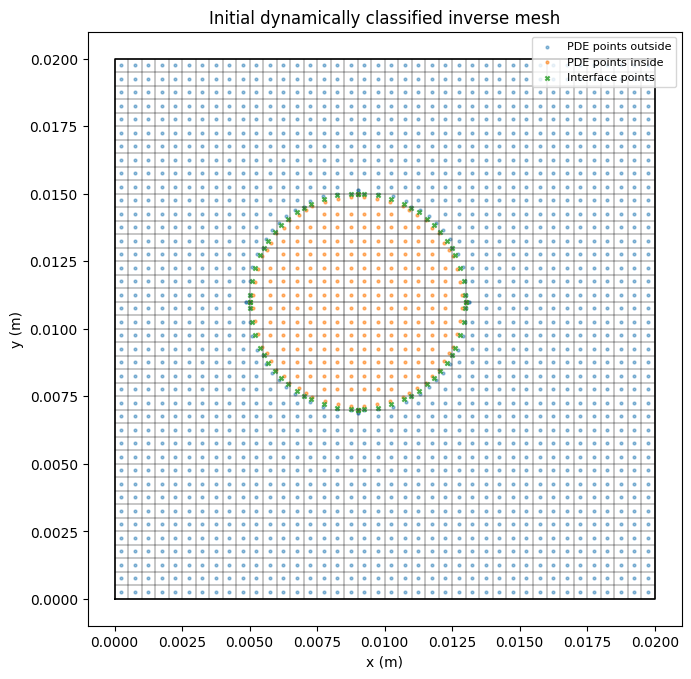

✅ 网格数据导出完成 | 文件夹：inverse_adaptive_data\00_initial_inverse_mesh


'inverse_adaptive_data\\00_initial_inverse_mesh'

In [19]:
EXPORT_ROOT = "inverse_adaptive_data"
os.makedirs(EXPORT_ROOT, exist_ok=True)

# 建立初始背景 leaf cells。后续保留细化拓扑，但每次几何更新都清除旧圆的分类信息。
all_cells = build_initial_cells(params, nx0=40, ny0=40)

GEOMETRY_REFRESH_EVERY = 1  # 必须为 1：每次几何更新后都重新识别内外点

def _clear_stale_cell_geometry(cells):
    stale_keys = (
        "region", "is_interface", "interface_length",
        "area_out", "area_in", "w_gamma",
        "R_out2", "R_in2", "R_if2",
        "R_out2_norm", "R_in2_norm", "R_if2_norm",
        "C_out_norm", "C_in_norm", "C_if_norm", "eta", "eta2",
    )
    for cell in cells:
        for key in stale_keys:
            cell.pop(key, None)

def rebuild_geometry_dependent_points(verbose=False):
    """
    按 params 中的当前圆，对全部 leaf cells 重新识别并生成训练点。
    该函数会替换所有旧的 x_dom_out/x_dom_in/theta_if，不沿用旧圆的点。
    """
    global out_sample, in_sample, interface_sample, out_cells, in_cells
    global x_dom_out, y_dom_out, x_dom_in, y_dom_in, x_if, y_if, theta_if
    global x_out_phys, y_out_phys, x_in_phys, y_in_phys, x_if_phys, y_if_phys

    _clear_stale_cell_geometry(all_cells)
    out_sample, in_sample, interface_sample, out_cells, in_cells = sample_points_from_matched_cells(
        all_cells, params, device, verbose=verbose)

    x_dom_out, y_dom_out = out_sample["x"], out_sample["y"]
    x_dom_in, y_dom_in = in_sample["x"], in_sample["y"]
    x_if, y_if = interface_sample["x"], interface_sample["y"]
    theta_if = torch.as_tensor(
        interface_sample["theta"], dtype=torch.get_default_dtype(), device=device).view(-1, 1)

    x_out_phys, y_out_phys = out_sample["x_phys"], out_sample["y_phys"]
    x_in_phys, y_in_phys = in_sample["x_phys"], in_sample["y_phys"]
    x_if_phys, y_if_phys = interface_sample["x_phys"], interface_sample["y_phys"]

    # 强制检查本轮重新识别结果，防止任何旧点或错误子域点进入下一轮损失。
    out_r2 = (x_out_phys - params["xc"]) ** 2 + (y_out_phys - params["yc"]) ** 2
    in_r2 = (x_in_phys - params["xc"]) ** 2 + (y_in_phys - params["yc"]) ** 2
    if np.any(out_r2 < params["R"] ** 2) or np.any(in_r2 >= params["R"] ** 2):
        raise RuntimeError("动态重分类失败：检测到 PDE 点被分配到错误子域。")
    if len(x_if_phys) > 0:
        interface_radius = np.sqrt(
            (x_if_phys - params["xc"]) ** 2 + (y_if_phys - params["yc"]) ** 2)
        if not np.allclose(interface_radius, params["R"], rtol=0.0, atol=1e-10):
            raise RuntimeError("动态重分类失败：界面点不位于当前圆上。")

    if verbose:
        print(f"Current geometry: xc={params['xc']:.8f}, yc={params['yc']:.8f}, R={params['R']:.8f}")

def refresh_after_geometry_update(verbose=False):
    """几何更新后的原子刷新：同步几何、重建 PDE/界面点、更新评价点路由。"""
    sync_geometry_to_params()
    rebuild_geometry_dependent_points(verbose=verbose)
    refresh_eval = globals().get("refresh_evaluation_partition")
    if callable(refresh_eval):
        refresh_eval(verbose=verbose)

rebuild_geometry_dependent_points(verbose=True)

plot_adaptive_sampling_circle(
    out_cells, in_cells, out_sample, in_sample, interface_sample, params,
    title="Initial dynamically classified inverse mesh",
    save_path="inverse_sampling_mesh_initial.png")

export_mesh_data_to_folder(
    save_root=EXPORT_ROOT,
    round_label="00_initial_inverse_mesh",
    out_cells=out_cells,
    in_cells=in_cells,
    out_sample=out_sample,
    in_sample=in_sample,
    interface_sample=interface_sample)

In [20]:
def calc_rel_l2(pred, true):
    numerator = np.linalg.norm(pred - true, ord=2)
    denominator = np.linalg.norm(true, ord=2)
    return 0.0 if denominator < 1e-12 else numerator / denominator

def load_data_simple_full_nd(file_path):
    data = np.loadtxt(file_path, skiprows=1, usecols=range(5), delimiter=",")
    print(f"成功读取数据: {data.shape[0]} 行, {data.shape[1]} 列")
    return data

def partition_evaluation_data(data_vals_nd, params):
    """仅用于误差评价；按当前反演圆分类，且不设置会丢点的容差区间。"""
    L, V_0, P_0 = params["L"], params["V_0"], params["P_0"]
    x, y = data_vals_nd[:, 0], data_vals_nd[:, 1]
    rr2 = (x - params["xc"]) ** 2 + (y - params["yc"]) ** 2
    mask_in = rr2 < params["R"] ** 2
    mask_out = ~mask_in

    inside_phys = data_vals_nd[mask_in]
    outside_phys = data_vals_nd[mask_out]

    def to_nd(arr):
        out = arr.copy()
        out[:, 0] = arr[:, 0] / L * 2.0 - 1.0
        out[:, 1] = arr[:, 1] / L * 2.0 - 1.0
        out[:, 2] = arr[:, 2] / V_0
        out[:, 3] = arr[:, 3] / V_0
        out[:, 4] = arr[:, 4] / P_0
        return out

    return inside_phys, outside_phys, to_nd(inside_phys), to_nd(outside_phys)

@torch.no_grad()
def predict_regions(net_out, net_in, inside_coords, outside_coords, params):
    uo, vo, po = forward_with_hard_bc(net_out, outside_coords, params)
    ui, vi, pi = forward_inside_free(net_in, inside_coords)
    return {
        "pred_out": torch.cat([uo, vo, po], dim=1).cpu().numpy(),
        "pred_in": torch.cat([ui, vi, pi], dim=1).cpu().numpy(),
        "true_out": outside_uvp.cpu().numpy(),
        "true_in": inside_uvp.cpu().numpy(),
        "coords_out": outside_coords.cpu().numpy(),
        "coords_in": inside_coords.cpu().numpy(),
    }

FEM_FILE = "data.csv"
HAS_FEM_DATA = os.path.exists(FEM_FILE)

def refresh_evaluation_partition(verbose=False):
    global inside_phys, outside_phys, inside_nd, outside_nd
    global inside_coords, inside_uvp, outside_coords, outside_uvp
    if not HAS_FEM_DATA:
        return
    inside_phys, outside_phys, inside_nd, outside_nd = partition_evaluation_data(data_vals, params)
    inside_coords = torch.as_tensor(inside_nd[:, :2], dtype=torch.get_default_dtype(), device=device)
    inside_uvp = torch.as_tensor(inside_nd[:, 2:], dtype=torch.get_default_dtype(), device=device)
    outside_coords = torch.as_tensor(outside_nd[:, :2], dtype=torch.get_default_dtype(), device=device)
    outside_uvp = torch.as_tensor(outside_nd[:, 2:], dtype=torch.get_default_dtype(), device=device)
    if verbose:
        print(f"评价点按当前圆重新分域: inside={len(inside_coords)}, outside={len(outside_coords)}")

if HAS_FEM_DATA:
    data_vals = load_data_simple_full_nd(FEM_FILE)
    refresh_evaluation_partition(verbose=True)
else:
    print(f"未找到 {FEM_FILE}，将跳过数据损失和 L2 评价。")

成功读取数据: 40169 行, 5 列
评价点按当前圆重新分域: inside=5001, outside=35168


In [21]:
N_DATA = 50
SMOOTH_WIDTH_STAR = 2.0 * 2.0e-4 / params["L"]

if HAS_FEM_DATA:
    data_all_nd = data_vals.copy()
    data_all_nd[:, 0] = data_vals[:, 0] / params["L"] * 2.0 - 1.0
    data_all_nd[:, 1] = data_vals[:, 1] / params["L"] * 2.0 - 1.0
    data_all_nd[:, 2] = data_vals[:, 2] / params["V_0"]
    data_all_nd[:, 3] = data_vals[:, 3] / params["V_0"]
    data_all_nd[:, 4] = data_vals[:, 4] / params["P_0"]

    all_coords_obs_pool = torch.tensor(data_all_nd[:, :2], dtype=torch.get_default_dtype(), device=device)
    all_uvp_obs_pool = torch.tensor(data_all_nd[:, 2:], dtype=torch.get_default_dtype(), device=device)
    # 使用 CPU 生成固定索引，再转到当前设备，兼容 CPU/CUDA 及不同 PyTorch 版本。
    generator = torch.Generator().manual_seed(42)
    obs_index = torch.randperm(len(all_coords_obs_pool), generator=generator)[:min(N_DATA, len(all_coords_obs_pool))].to(device)
    coords_obs = all_coords_obs_pool[obs_index]
    uvp_obs = all_uvp_obs_pool[obs_index]
    print(f"全域固定观测点数量: {len(coords_obs)}")

def smooth_inside_weight(coords):
    """当前圆内权重约为1，圆外权重约为0；对 xc、yc、R 可微。"""
    xc_star, yc_star, R_star = current_geometry_star()
    distance = torch.sqrt(
        (coords[:, 0:1] - xc_star) ** 2
        + (coords[:, 1:2] - yc_star) ** 2
        + 1e-12
    ) - R_star
    return torch.sigmoid(-distance / SMOOTH_WIDTH_STAR)

def differentiable_interface_points(theta):
    xc_star, yc_star, R_star = current_geometry_star()
    return xc_star + R_star * torch.cos(theta), yc_star + R_star * torch.sin(theta)

def data_loss(
    inside_coords,
    outside_coords,
    net_out,
    net_hole,
    params,
    n_data_out=None,
    n_data_in=None,
    seed=42
):
    weight_in = smooth_inside_weight(coords_obs)

    u_out, v_out, p_out = forward_with_hard_bc(net_out, coords_obs, params)
    u_in, v_in, p_in = forward_inside_free(net_hole, coords_obs)
    pred_out = torch.cat([u_out, v_out, p_out], dim=1)
    pred_in = torch.cat([u_in, v_in, p_in], dim=1)

    pred = (1.0 - weight_in) * pred_out + weight_in * pred_in
    err2 = torch.sum((pred - uvp_obs) ** 2, dim=1, keepdim=True)

    loss_out = torch.mean((1.0 - weight_in) * err2)
    loss_in = torch.mean(weight_in * err2)
    return loss_out + loss_in, loss_out, loss_in

全域固定观测点数量: 50


In [22]:
def compute_total_loss(data,params, w_pde_out=1.0,w_pde_in=1.0,w_if=1.0,w_data=20.0):
    x_out_dom, y_out_dom = data["dom_out"]
    r_c_out, r_mx_out, r_my_out = governing_equations_out(
        net_out, x_out_dom, y_out_dom, params)
    loss_pde_out = (
        (r_c_out ** 2).mean()
        + (r_mx_out ** 2).mean()
        + (r_my_out ** 2).mean())

    x_in_dom, y_in_dom = data["dom_in"]
    r_c_in, r_mx_in, r_my_in = governing_equations_in(
        net_in, x_in_dom, y_in_dom, params )
    loss_pde_in = (
        (r_c_in ** 2).mean()
        + (r_mx_in ** 2).mean()
        + (r_my_in ** 2).mean() )

    theta_current = data["interface_theta"]
    x_if_current, y_if_current = differentiable_interface_points(theta_current)
    loss_u_n, loss_jump_x, loss_jump_y, _ = interface_loss(
        net_out, net_in, x_if_current, y_if_current, params, device)
    loss_if = loss_u_n + loss_jump_x + loss_jump_y

    if HAS_FEM_DATA:
            loss_data, loss_data_out, loss_data_in = data_loss(
                inside_coords,
                outside_coords,
                net_out,
                net_in,
                params )
    else:
        loss_data = torch.tensor(
            0.0,
            dtype=torch.get_default_dtype(),
            device=device)
        loss_data_out = loss_data
        loss_data_in = loss_data

    total_loss = (
        w_pde_out * loss_pde_out
        + w_pde_in * loss_pde_in
        + w_if * loss_if
        + w_data * loss_data)

    loss_dict = {
        "L_pde_out": loss_pde_out.item(),
        "L_pde_in": loss_pde_in.item(),
        "L_if_total": loss_if.item(),
        "L_data": loss_data.item(),
        "L_data_out": loss_data_out.item(),
        "L_data_in": loss_data_in.item(),
        "total": total_loss.item(),
        "rc_out": (r_c_out ** 2).mean().item(),
        "rmx_out": (r_mx_out ** 2).mean().item(),
        "rmy_out": (r_my_out ** 2).mean().item(),
        "rc_in": (r_c_in ** 2).mean().item(),
        "rmx_in": (r_mx_in ** 2).mean().item(),
        "rmy_in": (r_my_in ** 2).mean().item(),
        "L_if_u_n": loss_u_n.item(),
        "loss_jump_x": loss_jump_x.item(),
        "loss_jump_y": loss_jump_y.item(),
    }

    return total_loss, loss_dict

def make_training_points():
    return {
        "dom_out": (x_dom_out, y_dom_out),
        "dom_in": (x_dom_in, y_dom_in),
        "interface_theta": theta_if,
    }

In [23]:
global_step = 0

loss_history = {
    "step": [],
    "total": [],
    "pde_out": [],
    "pde_in": [],
    "if_T": [],
    "data": [],
    "phase": []
}

geometry_history = {
    "step": [],
    "xc": [],
    "yc": [],
    "R": [],
    "phase": []
}

l2_error_history = {
    "step": [],
    "u_l2": [],
    "v_l2": [],
    "p_l2": [],
    "phase": []
}

[Adam] iter=     0, Total=2.038e+02, PDE-out=1.34e+01, PDE-in=5.01e+01, IF=3.70e+01, Data=5.16e+00, xc=0.0089971, yc=0.0109973, R=0.0039996
[Adam-L2] u=4.552791, v=0.693527, p=0.368905
[Adam] iter=   100, Total=7.919e-01, PDE-out=8.18e-02, PDE-in=1.68e-02, IF=4.59e-02, Data=3.24e-02, xc=0.0087366, yc=0.0108283, R=0.0039617
[Adam-L2] u=0.773218, v=0.199367, p=0.004355
[Adam] iter=   200, Total=3.083e-01, PDE-out=4.79e-02, PDE-in=1.77e-02, IF=6.07e-02, Data=9.10e-03, xc=0.0088887, yc=0.0105773, R=0.0039302
[Adam-L2] u=0.703270, v=0.150633, p=0.002900
[Adam] iter=   300, Total=1.728e-01, PDE-out=3.66e-02, PDE-in=6.44e-03, IF=6.89e-02, Data=3.04e-03, xc=0.0091220, yc=0.0103352, R=0.0038798
[Adam-L2] u=0.646764, v=0.133600, p=0.002656
[Adam] iter=   400, Total=1.256e-01, PDE-out=2.60e-02, PDE-in=4.27e-03, IF=5.08e-02, Data=2.22e-03, xc=0.0093929, yc=0.0101299, R=0.0038285
[Adam-L2] u=0.612807, v=0.138111, p=0.003529
[Adam] iter=   500, Total=9.278e-02, PDE-out=2.05e-02, PDE-in=3.34e-03, IF=

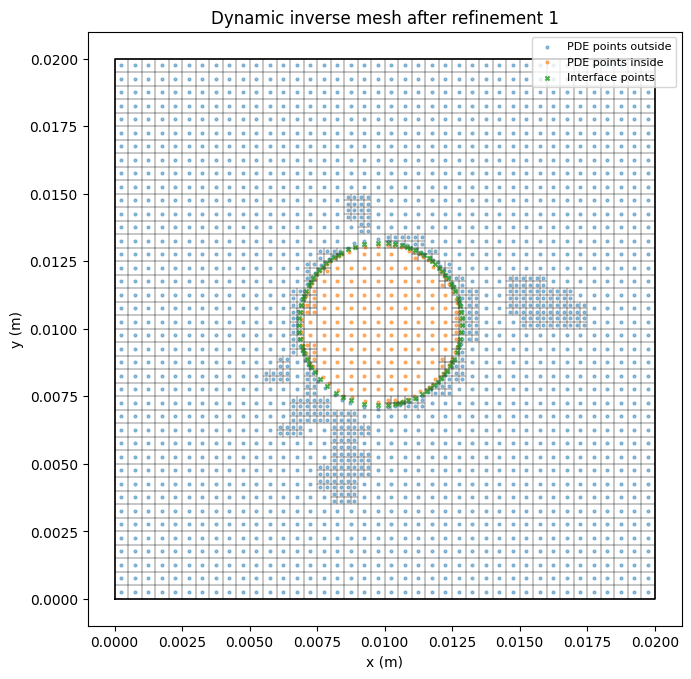

✅ 网格数据导出完成 | 文件夹：inverse_adaptive_data\inverse_refine_01
加密完成：残差加密=96, 2:1补加密=0, 界面点=84
[Adam] iter=  3000, Total=2.354e-02, PDE-out=1.30e-02, PDE-in=1.55e-03, IF=8.34e-04, Data=4.08e-04, xc=0.0098398, yc=0.0101706, R=0.0030140
[Adam-L2] u=0.288328, v=0.066464, p=0.002245
[Adam] iter=  3100, Total=1.416e-02, PDE-out=8.60e-03, PDE-in=8.17e-04, IF=7.67e-04, Data=1.99e-04, xc=0.0098178, yc=0.0101701, R=0.0030038
[Adam-L2] u=0.290871, v=0.070514, p=0.001543
[Adam] iter=  3200, Total=1.344e-02, PDE-out=8.34e-03, PDE-in=2.68e-03, IF=7.32e-04, Data=8.37e-05, xc=0.0098087, yc=0.0101795, R=0.0030147
[Adam-L2] u=0.294548, v=0.072484, p=0.000756
[Adam] iter=  3300, Total=3.809e-02, PDE-out=1.40e-02, PDE-in=1.44e-02, IF=9.90e-04, Data=4.32e-04, xc=0.0098225, yc=0.0101696, R=0.0030106
[Adam-L2] u=0.285808, v=0.070300, p=0.003184
[Adam] iter=  3400, Total=1.204e-02, PDE-out=7.26e-03, PDE-in=1.31e-04, IF=6.82e-04, Data=1.98e-04, xc=0.0098314, yc=0.0101551, R=0.0030021
[Adam-L2] u=0.279395, v=0.068410

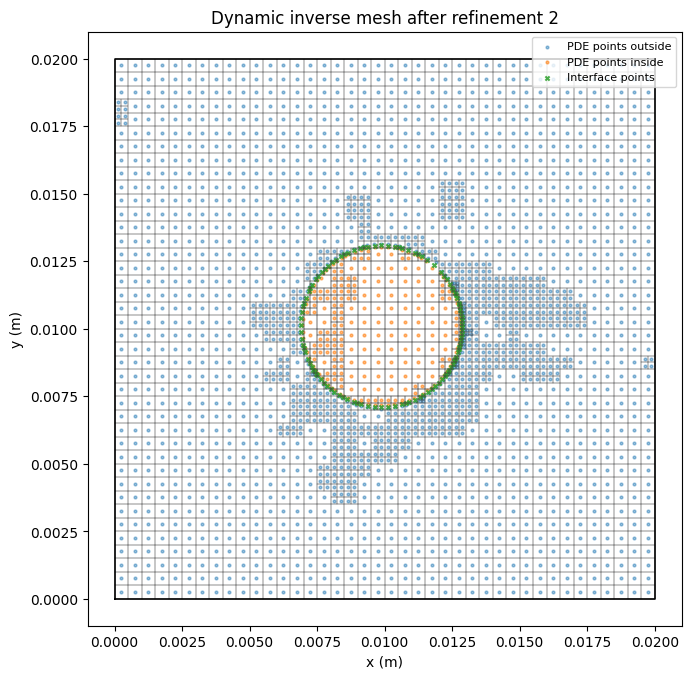

✅ 网格数据导出完成 | 文件夹：inverse_adaptive_data\inverse_refine_02
加密完成：残差加密=114, 2:1补加密=4, 界面点=109
[Adam] iter=  6000, Total=6.757e-03, PDE-out=4.78e-03, PDE-in=4.81e-05, IF=2.51e-04, Data=8.38e-05, xc=0.0098799, yc=0.0100896, R=0.0029885
[Adam-L2] u=0.237472, v=0.063318, p=0.000649
[Adam] iter=  6100, Total=6.387e-03, PDE-out=4.22e-03, PDE-in=4.86e-05, IF=2.83e-04, Data=9.19e-05, xc=0.0098676, yc=0.0100909, R=0.0029815
[Adam-L2] u=0.246408, v=0.065919, p=0.000526
[Adam] iter=  6200, Total=6.058e-03, PDE-out=3.97e-03, PDE-in=4.96e-05, IF=2.77e-04, Data=8.80e-05, xc=0.0098672, yc=0.0100860, R=0.0029839
[Adam-L2] u=0.245037, v=0.066644, p=0.000488
[Adam] iter=  6300, Total=7.777e-03, PDE-out=4.26e-03, PDE-in=3.17e-04, IF=2.82e-04, Data=1.46e-04, xc=0.0098689, yc=0.0100893, R=0.0029905
[Adam-L2] u=0.242311, v=0.067986, p=0.000483
[Adam] iter=  6400, Total=6.082e-03, PDE-out=4.06e-03, PDE-in=4.25e-05, IF=2.54e-04, Data=8.65e-05, xc=0.0098697, yc=0.0100825, R=0.0029909
[Adam-L2] u=0.239726, v=0.0662

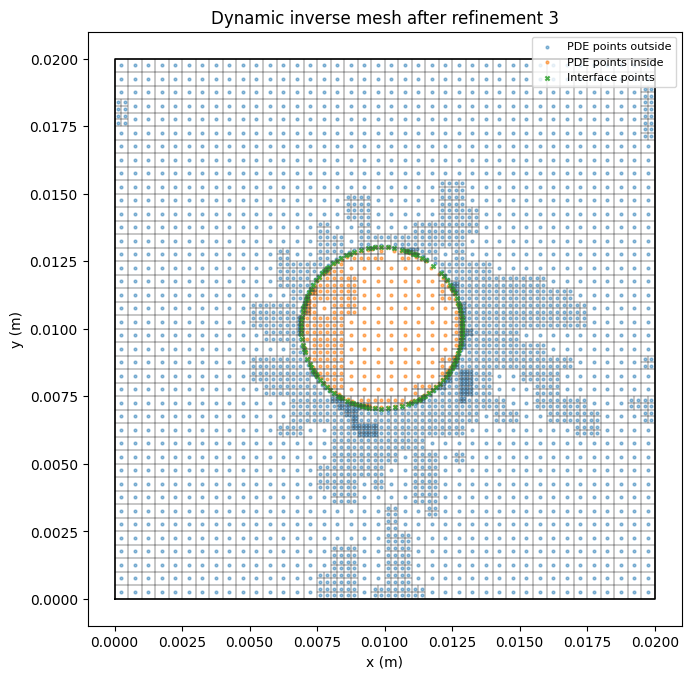

✅ 网格数据导出完成 | 文件夹：inverse_adaptive_data\inverse_refine_03
加密完成：残差加密=135, 2:1补加密=2, 界面点=128
[Adam] iter=  9000, Total=4.038e-03, PDE-out=2.85e-03, PDE-in=2.63e-05, IF=1.31e-04, Data=5.13e-05, xc=0.0098888, yc=0.0100293, R=0.0029887
[Adam-L2] u=0.224639, v=0.063587, p=0.000649
[Adam] iter=  9100, Total=5.655e-03, PDE-out=2.63e-03, PDE-in=7.98e-05, IF=2.32e-04, Data=1.36e-04, xc=0.0099073, yc=0.0100566, R=0.0029880
[Adam-L2] u=0.211199, v=0.061110, p=0.000491
[Adam] iter=  9200, Total=3.385e-03, PDE-out=1.97e-03, PDE-in=2.26e-05, IF=1.14e-04, Data=6.38e-05, xc=0.0099045, yc=0.0100448, R=0.0029882
[Adam-L2] u=0.207079, v=0.060570, p=0.000341
[Adam] iter=  9300, Total=3.513e-03, PDE-out=2.01e-03, PDE-in=1.76e-05, IF=1.20e-04, Data=6.81e-05, xc=0.0099037, yc=0.0100432, R=0.0029833
[Adam-L2] u=0.210057, v=0.061173, p=0.000489
[Adam] iter=  9400, Total=3.436e-03, PDE-out=2.01e-03, PDE-in=1.51e-05, IF=1.22e-04, Data=6.44e-05, xc=0.0099042, yc=0.0100420, R=0.0029812
[Adam-L2] u=0.209522, v=0.0608

In [24]:
network_params = list(net_out.parameters()) + list(net_in.parameters())
geometry_params = [geom_raw_xc, geom_raw_yc, geom_raw_R]

adam = torch.optim.Adam([
    {"params": network_params, "lr": 1e-3, "weight_decay": 1e-6},
    {"params": geometry_params, "lr": 5e-4, "weight_decay": 0.0},
])

scheduler = torch.optim.lr_scheduler.StepLR(
    adam, step_size=10000, gamma=1.0
)

num_iters_adam =10001
log_every = 100
refine_start = 2001
refine_every = 3000
max_refine_rounds = 3
mark_ratio = 0.06
max_refine_level = 3
area_n_side = 10
refine_round = 0

time_start = time.time()

for it in range(num_iters_adam + 1):

    # ==================== Adam 更新 ====================
    adam.zero_grad(set_to_none=True)

    total_loss, loss_dict = compute_total_loss(
        make_training_points(), params
    )

    total_loss.backward()

    torch.nn.utils.clip_grad_norm_(network_params, 1.0)
    torch.nn.utils.clip_grad_norm_(geometry_params, 0.01)

    adam.step()
    scheduler.step()
    global_step += 1

    # 每次几何更新后重新识别内外域点
    refresh_after_geometry_update(verbose=False)

    # ==================== 自适应加密 ====================
    if (
        it >= refine_start
        and it % refine_every == 0
        and refine_round < max_refine_rounds
        and it > 0
    ):
        print(f"\n开始第 {refine_round + 1} 轮加密：iter={it}")

        all_cells, refined_count, stats = (
            refine_cells_by_integral_residual(
                cells=all_cells,
                params=params,
                device=device,
                mark_ratio=mark_ratio,
                max_level=max_refine_level,
                lambda_gamma=LAMBDA_GAMMA,
                area_n_side=area_n_side,
            )
        )

        all_cells, balance_refined = balance_cells_2to1(
            all_cells,
            params=params,
            max_level=max_refine_level,
        )

        # 新网格按照当前圆重新分类
        rebuild_geometry_dependent_points(verbose=True)

        if HAS_FEM_DATA:
            refresh_evaluation_partition(verbose=True)

        refine_round += 1

        plot_adaptive_sampling_circle(
            out_cells, in_cells,
            out_sample, in_sample, interface_sample,
            params,
            title=f"Dynamic inverse mesh after refinement {refine_round}",
            save_path=f"inverse_mesh_refine_{refine_round}.png",
        )

        export_mesh_data_to_folder(
            save_root=EXPORT_ROOT,
            round_label=f"inverse_refine_{refine_round:02d}",
            out_cells=out_cells,
            in_cells=in_cells,
            out_sample=out_sample,
            in_sample=in_sample,
            interface_sample=interface_sample,
        )

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        print(
            f"加密完成：残差加密={refined_count}, "
            f"2:1补加密={balance_refined}, "
            f"界面点={len(x_if_phys)}"
        )

    # ==================== 保存 Adam 结果 ====================
    if it % log_every == 0:

        # 用更新后的网络、几何和点集重新计算损失
        total_eval, eval_dict = compute_total_loss(
            make_training_points(), params
        )

        loss_history["step"].append(global_step)
        loss_history["total"].append(total_eval.item())
        loss_history["pde_out"].append(eval_dict["L_pde_out"])
        loss_history["pde_in"].append(eval_dict["L_pde_in"])
        loss_history["if_T"].append(eval_dict["L_if_total"])
        loss_history["data"].append(eval_dict["L_data"])
        loss_history["phase"].append("adam")

        geometry_history["step"].append(global_step)
        geometry_history["xc"].append(params["xc"])
        geometry_history["yc"].append(params["yc"])
        geometry_history["R"].append(params["R"])
        geometry_history["phase"].append("adam")

        print(
            f"[Adam] iter={it:6d}, "
            f"Total={total_eval.item():.3e}, "
            f"PDE-out={eval_dict['L_pde_out']:.2e}, "
            f"PDE-in={eval_dict['L_pde_in']:.2e}, "
            f"IF={eval_dict['L_if_total']:.2e}, "
            f"Data={eval_dict['L_data']:.2e}, "
            f"xc={params['xc']:.7f}, "
            f"yc={params['yc']:.7f}, "
            f"R={params['R']:.7f}"
        )

        # ==================== L2 误差 ====================
        if HAS_FEM_DATA:
            pred = predict_regions(
                net_out, net_in,
                inside_coords, outside_coords,
                params,
            )

            pred_u = np.concatenate([
                pred["pred_out"][:, 0], pred["pred_in"][:, 0]
            ])
            pred_v = np.concatenate([
                pred["pred_out"][:, 1], pred["pred_in"][:, 1]
            ])
            pred_p = np.concatenate([
                pred["pred_out"][:, 2], pred["pred_in"][:, 2]
            ])

            true_u = np.concatenate([
                pred["true_out"][:, 0], pred["true_in"][:, 0]
            ])
            true_v = np.concatenate([
                pred["true_out"][:, 1], pred["true_in"][:, 1]
            ])
            true_p = np.concatenate([
                pred["true_out"][:, 2], pred["true_in"][:, 2]
            ])

            u_l2 = calc_rel_l2(pred_u, true_u)
            v_l2 = calc_rel_l2(pred_v, true_v)
            p_l2 = calc_rel_l2(pred_p, true_p)

            l2_error_history["step"].append(global_step)
            l2_error_history["u_l2"].append(u_l2)
            l2_error_history["v_l2"].append(v_l2)
            l2_error_history["p_l2"].append(p_l2)
            l2_error_history["phase"].append("adam")

            print(
                f"[Adam-L2] u={u_l2:.6f}, "
                f"v={v_l2:.6f}, p={p_l2:.6f}"
            )

        del total_eval

adam_end_step = global_step

print(f"Total Adam time: {time.time() - time_start:.2f} s")

In [25]:
# ============================================================
# L-BFGS：固定几何，仅优化网络
# ============================================================

# 兼容前面没有 phase 的历史字典
loss_history.setdefault(
    "phase", ["adam"] * len(loss_history["step"]))
geometry_history.setdefault(
    "phase", ["adam"] * len(geometry_history["step"]))
l2_error_history.setdefault(
    "phase", ["adam"] * len(l2_error_history["step"]))

# 冻结 Adam 反演得到的几何
for parameter in geometry_params:
    parameter.requires_grad_(False)

# 根据最终几何更新一次点集，随后保持不变
refresh_after_geometry_update(verbose=True)
data_lbfgs = make_training_points()

lbfgs = torch.optim.LBFGS(
    network_params,
    lr=1.0,
    max_iter=50,
    tolerance_grad=1e-7,
    tolerance_change=1e-10,
    history_size=50,
    line_search_fn="strong_wolfe",
)

num_iters_lbfgs = 1000
lbfgs_closure_calls = 0
lbfgs_l2_every = 10

print("\n====== Start L-BFGS refinement ======\n")


def closure():
    global lbfgs_closure_calls

    lbfgs.zero_grad(set_to_none=True)

    loss, _ = compute_total_loss(
        data_lbfgs, params
    )

    loss.backward()
    lbfgs_closure_calls += 1

    return loss


for it in range(num_iters_lbfgs):

    # 一次外层迭代可能多次调用 closure
    lbfgs.step(closure)

    # 只把接受后的外层迭代计入 global_step
    global_step += 1

    # 重新计算接受状态下的损失
    # 这里不能使用 torch.no_grad()，因为 PDE 需要坐标导数
    total_eval, loss_dict = compute_total_loss(
        data_lbfgs, params
    )

    # ==================== 保存损失 ====================
    loss_history["step"].append(global_step)
    loss_history["total"].append(total_eval.item())
    loss_history["pde_out"].append(
        loss_dict["L_pde_out"]
    )
    loss_history["pde_in"].append(
        loss_dict["L_pde_in"]
    )
    loss_history["if_T"].append(
        loss_dict["L_if_total"]
    )
    loss_history["data"].append(
        loss_dict["L_data"]
    )
    loss_history["phase"].append("lbfgs")

    # ==================== 保存几何参数 ====================
    # 因为几何被冻结，所以第二阶段为水平线
    geometry_history["step"].append(global_step)
    geometry_history["xc"].append(params["xc"])
    geometry_history["yc"].append(params["yc"])
    geometry_history["R"].append(params["R"])
    geometry_history["phase"].append("lbfgs")

    # ==================== 保存 L2 误差 ====================
    if (
        HAS_FEM_DATA
        and ((it + 1) % lbfgs_l2_every == 0 or it == 0)
    ):
        pred = predict_regions(
            net_out, net_in,
            inside_coords, outside_coords,
            params,
        )

        pred_u = np.concatenate([
            pred["pred_out"][:, 0],
            pred["pred_in"][:, 0],
        ])
        pred_v = np.concatenate([
            pred["pred_out"][:, 1],
            pred["pred_in"][:, 1],
        ])
        pred_p = np.concatenate([
            pred["pred_out"][:, 2],
            pred["pred_in"][:, 2],
        ])

        true_u = np.concatenate([
            pred["true_out"][:, 0],
            pred["true_in"][:, 0],
        ])
        true_v = np.concatenate([
            pred["true_out"][:, 1],
            pred["true_in"][:, 1],
        ])
        true_p = np.concatenate([
            pred["true_out"][:, 2],
            pred["true_in"][:, 2],
        ])

        u_l2 = calc_rel_l2(pred_u, true_u)
        v_l2 = calc_rel_l2(pred_v, true_v)
        p_l2 = calc_rel_l2(pred_p, true_p)

        l2_error_history["step"].append(global_step)
        l2_error_history["u_l2"].append(u_l2)
        l2_error_history["v_l2"].append(v_l2)
        l2_error_history["p_l2"].append(p_l2)
        l2_error_history["phase"].append("lbfgs")

    # ==================== 打印 ====================
    if (it + 1) % 10 == 0 or it == 0:
        print(
            f"[L-BFGS] outer={it + 1:4d}/"
            f"{num_iters_lbfgs}, "
            f"closure={lbfgs_closure_calls:6d}, "
            f"Total={total_eval.item():.3e}, "
            f"PDE-out={loss_dict['L_pde_out']:.2e}, "
            f"PDE-in={loss_dict['L_pde_in']:.2e}, "
            f"IF={loss_dict['L_if_total']:.2e}, "
            f"Data={loss_dict['L_data']:.2e}, "
            f"xc={params['xc']:.7f}, "
            f"yc={params['yc']:.7f}, "
            f"R={params['R']:.7f}"
        )

        if HAS_FEM_DATA and (
            (it + 1) % lbfgs_l2_every == 0 or it == 0
        ):
            print(
                f"[L-BFGS-L2] "
                f"u={u_l2:.6f}, "
                f"v={v_l2:.6f}, "
                f"p={p_l2:.6f}"
            )

    del total_eval


# ============================================================
# 保存 Adam + L-BFGS 两阶段数据
# ============================================================

sync_geometry_to_params()
refresh_evaluation_partition(verbose=True)

pd.DataFrame(loss_history).to_csv(
    "loss_history_two_stage.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame(geometry_history).to_csv(
    "geometry_history_two_stage.csv",
    index=False,
    encoding="utf-8-sig",
)

if len(l2_error_history["step"]) > 0:
    pd.DataFrame(l2_error_history).to_csv(
        "l2_error_history_two_stage.csv",
        index=False,
        encoding="utf-8-sig",
    )

print(
    "Final inverse geometry:",
    {key: params[key] for key in ("xc", "yc", "R")},
)

print("已保存 Adam + L-BFGS 两阶段损失、几何参数和 L2 误差。")

========== 基于界面 cell 的匹配采样完成 ==========
leaf cell 数量: 2653
界面 cell 数量: 128
孔外 PDE 点数量: 2447
孔内 PDE 点数量: 334
界面点数量: 128
Current geometry: xc=0.00991137, yc=0.01003860, R=0.00297963
评价点按当前圆重新分域: inside=2773, outside=37396

====== Start L-BFGS refinement ======

[L-BFGS] outer=   1/1000, closure=    52, Total=1.492e-03, PDE-out=1.23e-03, PDE-in=1.40e-05, IF=8.49e-05, Data=8.18e-06, xc=0.0099114, yc=0.0100386, R=0.0029796
[L-BFGS-L2] u=0.205605, v=0.058718, p=0.000187
[L-BFGS] outer=  10/1000, closure=   545, Total=3.806e-04, PDE-out=2.93e-04, PDE-in=1.18e-05, IF=2.56e-05, Data=2.51e-06, xc=0.0099114, yc=0.0100386, R=0.0029796
[L-BFGS-L2] u=0.213733, v=0.060767, p=0.000111
[L-BFGS] outer=  20/1000, closure=  1086, Total=2.021e-04, PDE-out=1.50e-04, PDE-in=7.85e-06, IF=2.18e-05, Data=1.14e-06, xc=0.0099114, yc=0.0100386, R=0.0029796
[L-BFGS-L2] u=0.218166, v=0.061549, p=0.000088
[L-BFGS] outer=  30/1000, closure=  1639, Total=1.398e-04, PDE-out=9.87e-05, PDE-in=5.27e-06, IF=1.86e-05, Data=8

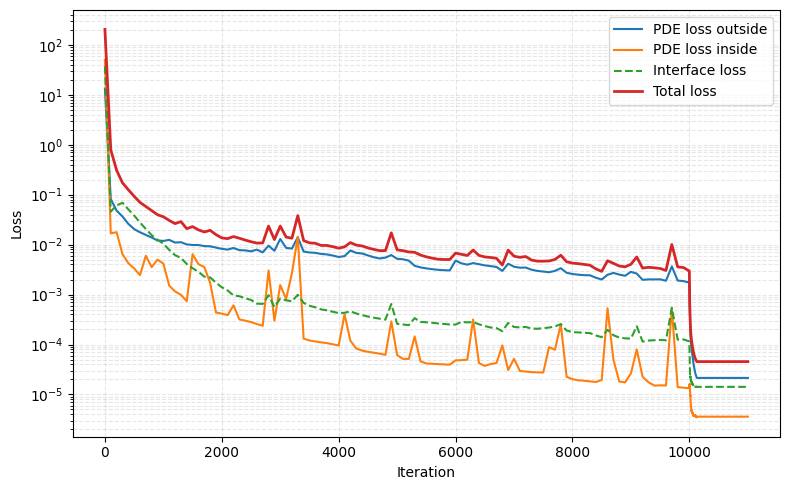

损失函数已保存到：loss_history.csv
L2误差已保存到：loss_l2.csv


In [26]:
def plot_loss_curves(loss_history):
    steps = np.asarray(loss_history["step"])
    plt.figure(figsize=(8, 5))
    plt.semilogy(steps, loss_history["pde_out"], label="PDE loss outside")
    plt.semilogy(steps, loss_history["pde_in"], label="PDE loss inside")
    plt.semilogy(steps, loss_history["if_T"], label="Interface loss", linestyle="--")
    plt.semilogy(steps, loss_history["total"], label="Total loss", linewidth=2)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, which="both", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_loss_curves(loss_history)
pd.DataFrame(loss_history).to_csv("loss_history.csv", index=False)
print("损失函数已保存到：loss_history.csv")

if len(l2_error_history["step"]) > 0:
    pd.DataFrame(l2_error_history).to_csv("loss_l2.csv", index=False)
    print("L2误差已保存到：loss_l2.csv")


===== 圆形界面几何反演结果 =====
  parameter  true_value_m  initial_value_m  identified_value_m  \
0        xc         0.010            0.009            0.009911   
1        yc         0.010            0.011            0.010039   
2         R         0.003            0.004            0.002980   

   absolute_error_m  relative_error_percent  
0          0.000089                0.886276  
1          0.000039                0.385990  
2          0.000020                0.679011  
几何参数历史已保存到：geometry_history.csv
最终反演结果已保存到：geometry_inverse_result.csv


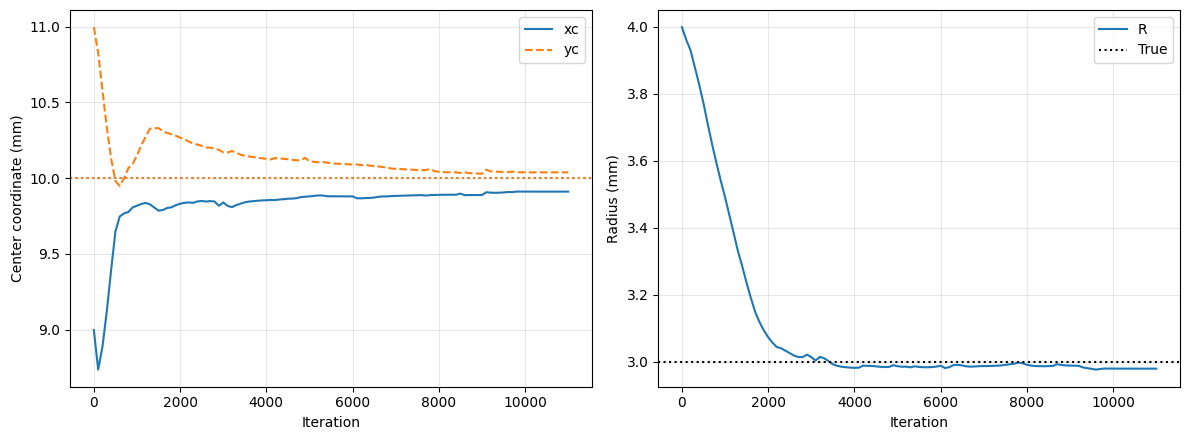

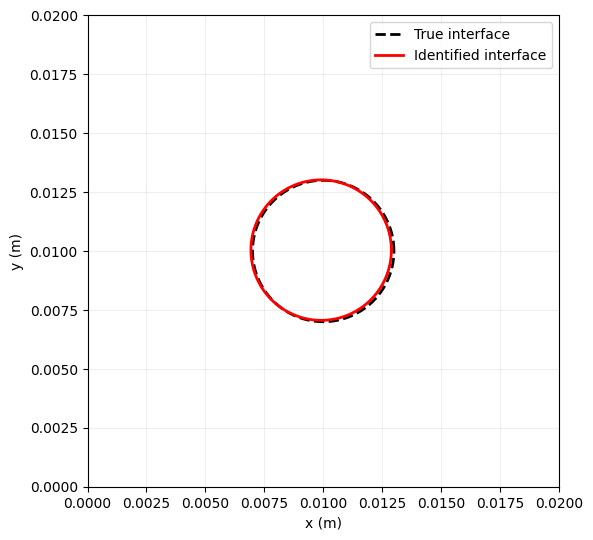

In [27]:
def plot_geometry_curves(geometry_history, params):
    steps = np.asarray(geometry_history["step"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(steps, np.asarray(geometry_history["xc"]) * 1e3, label="xc")
    axes[0].plot(steps, np.asarray(geometry_history["yc"]) * 1e3, label="yc", linestyle="--")
    axes[0].axhline(params["xc_true"] * 1e3, color="C0", linestyle=":")
    axes[0].axhline(params["yc_true"] * 1e3, color="C1", linestyle=":")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Center coordinate (mm)")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(steps, np.asarray(geometry_history["R"]) * 1e3, label="R")
    axes[1].axhline(params["R_true"] * 1e3, color="k", linestyle=":", label="True")
    axes[1].set_xlabel("Iteration")
    axes[1].set_ylabel("Radius (mm)")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

sync_geometry_to_params()
pd.DataFrame(geometry_history).to_csv("geometry_history.csv", index=False, encoding="utf-8-sig")

geometry_result = pd.DataFrame({
    "parameter": ["xc", "yc", "R"],
    "true_value_m": [params["xc_true"], params["yc_true"], params["R_true"]],
    "initial_value_m": [GEOM_INIT["xc"], GEOM_INIT["yc"], GEOM_INIT["R"]],
    "identified_value_m": [params["xc"], params["yc"], params["R"]],
})
geometry_result["absolute_error_m"] = np.abs(
    geometry_result["identified_value_m"] - geometry_result["true_value_m"]
)
geometry_result["relative_error_percent"] = 100.0 * geometry_result["absolute_error_m"] / np.abs(
    geometry_result["true_value_m"]
)
geometry_result.to_csv("geometry_inverse_result.csv", index=False, encoding="utf-8-sig")
print("\n===== 圆形界面几何反演结果 =====")
print(geometry_result)
print("几何参数历史已保存到：geometry_history.csv")
print("最终反演结果已保存到：geometry_inverse_result.csv")
plot_geometry_curves(geometry_history, params)

# 真实圆与反演圆对比
theta_plot = np.linspace(0.0, 2.0 * np.pi, 400)
plt.figure(figsize=(6, 6))
plt.plot(
    params["xc_true"] + params["R_true"] * np.cos(theta_plot),
    params["yc_true"] + params["R_true"] * np.sin(theta_plot),
    "k--", linewidth=2, label="True interface"
)
plt.plot(
    params["xc"] + params["R"] * np.cos(theta_plot),
    params["yc"] + params["R"] * np.sin(theta_plot),
    "r-", linewidth=2, label="Identified interface"
)
plt.xlim(0.0, params["L"])
plt.ylim(0.0, params["L"])
plt.gca().set_aspect("equal")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [28]:
# ============================================================
# 保存背景正方形、真实圆和反演圆的绘图坐标
# ============================================================

theta_plot = np.linspace(0.0, 2.0 * np.pi, 400)

# 背景正方形边界坐标：首尾点重复，用于闭合
background_x = np.array([
    0.0,
    params["L"],
    params["L"],
    0.0,
    0.0
])

background_y = np.array([
    0.0,
    0.0,
    params["L"],
    params["L"],
    0.0
])

# 真实圆坐标
true_x = (
    params["xc_true"]
    + params["R_true"] * np.cos(theta_plot)
)
true_y = (
    params["yc_true"]
    + params["R_true"] * np.sin(theta_plot)
)

# 反演圆坐标
identified_x = (
    params["xc"]
    + params["R"] * np.cos(theta_plot)
)
identified_y = (
    params["yc"]
    + params["R"] * np.sin(theta_plot)
)

# 使用 Series 自动补齐不同长度的数据列
interface_plot_data = pd.DataFrame({
    "background_x_m": pd.Series(background_x),
    "background_y_m": pd.Series(background_y),
    "true_x_m": pd.Series(true_x),
    "true_y_m": pd.Series(true_y),
    "identified_x_m": pd.Series(identified_x),
    "identified_y_m": pd.Series(identified_y),
})

interface_plot_data.to_csv(
    "circle_and_background_plot_data.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "背景边界及圆形界面数据已保存到："
    "circle_and_background_plot_data.csv"
)

背景边界及圆形界面数据已保存到：circle_and_background_plot_data.csv
